<a href="https://colab.research.google.com/github/salmantegar26-rgb/salmantegar/blob/main/StudentsPerformance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATA LOADING

Memasukkan data dari file ke dalam Python agar bisa diolah, biasanya dalam bentuk tabel (DataFrame).

In [21]:
# DATA LOADING
# Memastikan data layak dipakai sebelum dianalisis.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset
df = pd.read_csv("StudentsPerformance.csv")

print("Ukuran dataset:", df.shape)
print("\n5 data pertama:")
print(df.head())

print("\nInformasi dataset:")
df.info()

Ukuran dataset: (1000, 8)

5 data pertama:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 c

DATA CLEANING

Membersihkan data dari masalah kualitas supaya model tidak belajar dari data yang salah atau berantakan.

Shape awal: (1000, 8)
gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object
['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']
Missing value per kolom:
 gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64 

Jumlah duplikat: 0
gender -> ['female', 'male']
race_ethnicity -> ['group a', 'group b', 'group c', 'group d', 'group e']
parental_level_of_education -> ["associate's degree", "bachelor's degree", 'high school',

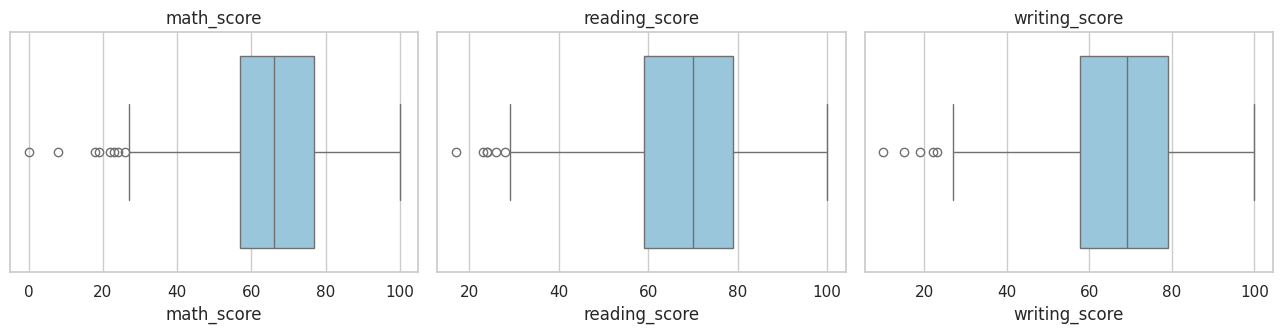

Shape setelah cleaning: (1000, 8)


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("StudentsPerformance.csv")
print("Shape awal:", df.shape)
print(df.dtypes)
df.head()

# %%
# 1. Standarisasi nama kolom (huruf kecil, spasi dan "/" diganti "_")
df.columns = (df.columns.str.strip().str.lower()
              .str.replace("/", "_").str.replace(" ", "_"))
print(list(df.columns))

# %%
# 2. Cek missing value dan duplikat
print("Missing value per kolom:\n", df.isna().sum(), "\n")
print("Jumlah duplikat:", df.duplicated().sum())

# %%
# 3. Cek konsistensi kategori (rapikan spasi dan huruf besar/kecil)
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
for c in cat_cols:
    df[c] = df[c].str.strip().str.lower()
    print(c, "->", sorted(df[c].unique()))

# %%
# 4. Validasi rentang nilai (skor harus 0-100)
score_cols = ["math_score", "reading_score", "writing_score"]
print("Nilai di luar 0-100:", ((df[score_cols] < 0) | (df[score_cols] > 100)).sum().sum())

# %%
# 5. Deteksi outlier dengan metode IQR (hanya dilaporkan, tidak dihapus)
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]

for c in score_cols:
    o = iqr_outliers(df[c])
    print(f"{c}: {len(o)} outlier (min={o.min() if len(o) else '-'}, max={o.max() if len(o) else '-'})")

print("\nSiswa dengan math_score = 0:")
print(df[df.math_score == 0])

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for a, c in zip(ax, score_cols):
    sns.boxplot(x=df[c], ax=a, color="#8ecae6")
    a.set_title(c)
plt.tight_layout()
plt.show()

# %%
# 6. Dataset bersih
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Shape setelah cleaning:", df_clean.shape)

TRANSFORMASI DATA

Mengubah data ke bentuk yang bisa dipahami model.

In [ ]:
# %%
import pandas as pd
import numpy as np

# Memastikan df_clean terdefinisi jika sel sebelumnya belum dieksekusi di sesi ini
try:
    df_clean
except NameError:
    df = pd.read_csv("StudentsPerformance.csv")
    df.columns = (df.columns.str.strip().str.lower()
                  .str.replace("/", "_").str.replace(" ", "_"))
    for c in df.select_dtypes(exclude="number").columns:
        df[c] = df[c].str.strip().str.lower()
    df_clean = df.drop_duplicates().reset_index(drop=True)

d = df_clean.copy()
score_cols = ["math_score", "reading_score", "writing_score"]

# %%
# 1. Feature engineering: fitur baru dari skor yang ada
d["average_score"] = d[score_cols].mean(axis=1).round(2)

# Lulus semua mata pelajaran (batas lulus 60)
d["pass_all"] = (d[score_cols] >= 60).all(axis=1).astype(int)

print(d[["math_score", "reading_score", "writing_score", "average_score", "pass_all"]].head())
print("\nProporsi lulus semua mapel:", d.pass_all.mean().round(3))

# %%
# 2. Encoding ordinal: pendidikan orang tua punya urutan tingkat
edu_order = ["some high school", "high school", "some college",
             "associate's degree", "bachelor's degree", "master's degree"]

d["parent_edu_ord"] = d["parental_level_of_education"].map(
    {e: i for i, e in enumerate(edu_order)}
)
print(d[["parental_level_of_education", "parent_edu_ord"]].drop_duplicates().sort_values("parent_edu_ord"))

# %%
# 3. Encoding one-hot: kategori tanpa urutan (drop_first untuk menghindari multikolinearitas)
ohe_cols = ["gender", "race_ethnicity", "lunch", "test_preparation_course"]
d_encoded = pd.get_dummies(d, columns=ohe_cols, drop_first=True, dtype=int)
print(d_encoded.columns.tolist())
d_encoded.head()

# %%
# 4. Scaling (StandardScaler) untuk fitur numerik
from sklearn.preprocessing import StandardScaler

num_cols = ["reading_score", "writing_score"]
scaled = pd.DataFrame(StandardScaler().fit_transform(d[num_cols]),
                      columns=[c + "_scaled" for c in num_cols])
print(scaled.describe().loc[["mean", "std"]].round(3))

   math_score  reading_score  writing_score  average_score  pass_all
0          72             72             74          72.67         1
1          69             90             88          82.33         1
2          90             95             93          92.67         1
3          47             57             44          49.33         0
4          76             78             75          76.33         1

Proporsi lulus semua mapel: 0.603
   parental_level_of_education  parent_edu_ord
15            some high school               0
8                  high school               1
1                 some college               2
3           associate's degree               3
0            bachelor's degree               4
2              master's degree               5
['parental_level_of_education', 'math_score', 'reading_score', 'writing_score', 'average_score', 'pass_all', 'parent_edu_ord', 'gender_male', 'race_ethnicity_group b', 'race_ethnicity_group c', 'race_ethnicity_group d', 'r

**EDA**

mengenali karakter data lewat statistik dan visualisasi, sebelum membuat model. teks tebal

       math_score  reading_score  writing_score  average_score
count     1000.00        1000.00        1000.00        1000.00
mean        66.09          69.17          68.05          67.77
std         15.16          14.60          15.20          14.26
min          0.00          17.00          10.00           9.00
25%         57.00          59.00          57.75          58.33
50%         66.00          70.00          69.00          68.33
75%         77.00          79.00          79.00          77.67
max        100.00         100.00         100.00         100.00

Skewness:
 math_score      -0.279
reading_score   -0.259
writing_score   -0.289
dtype: float64


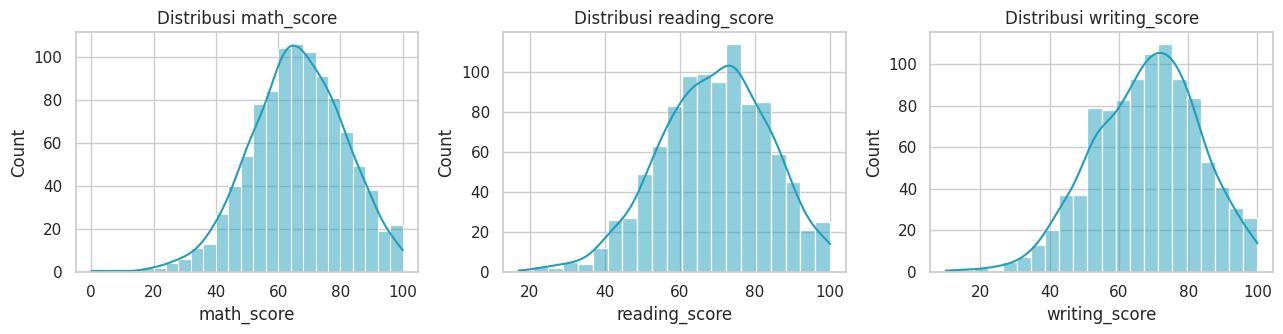

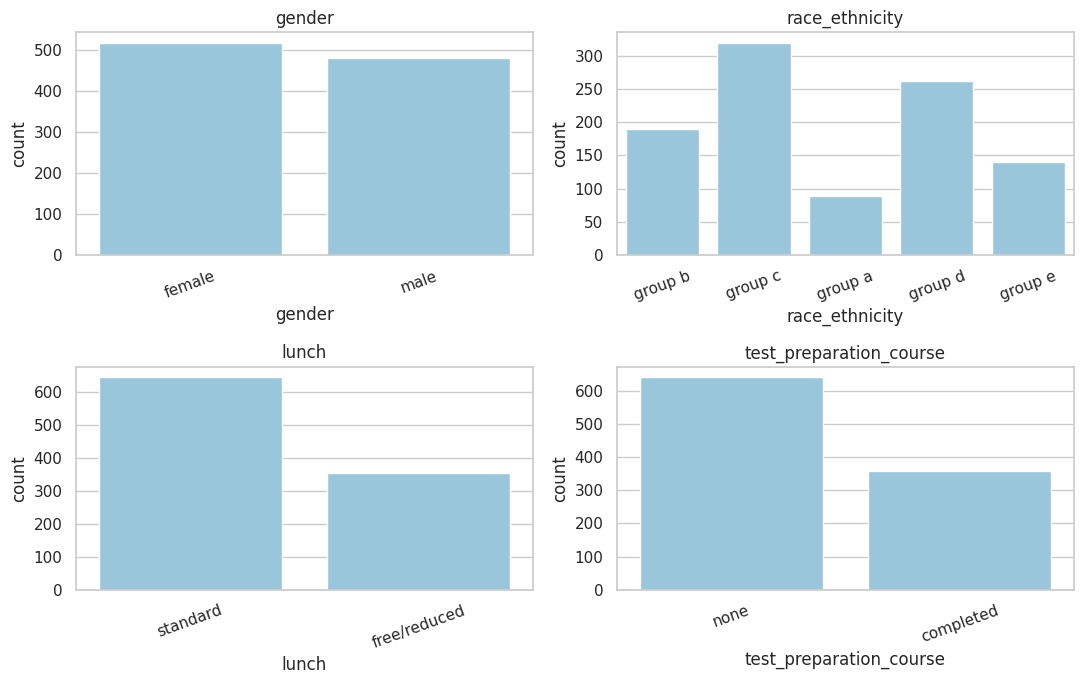

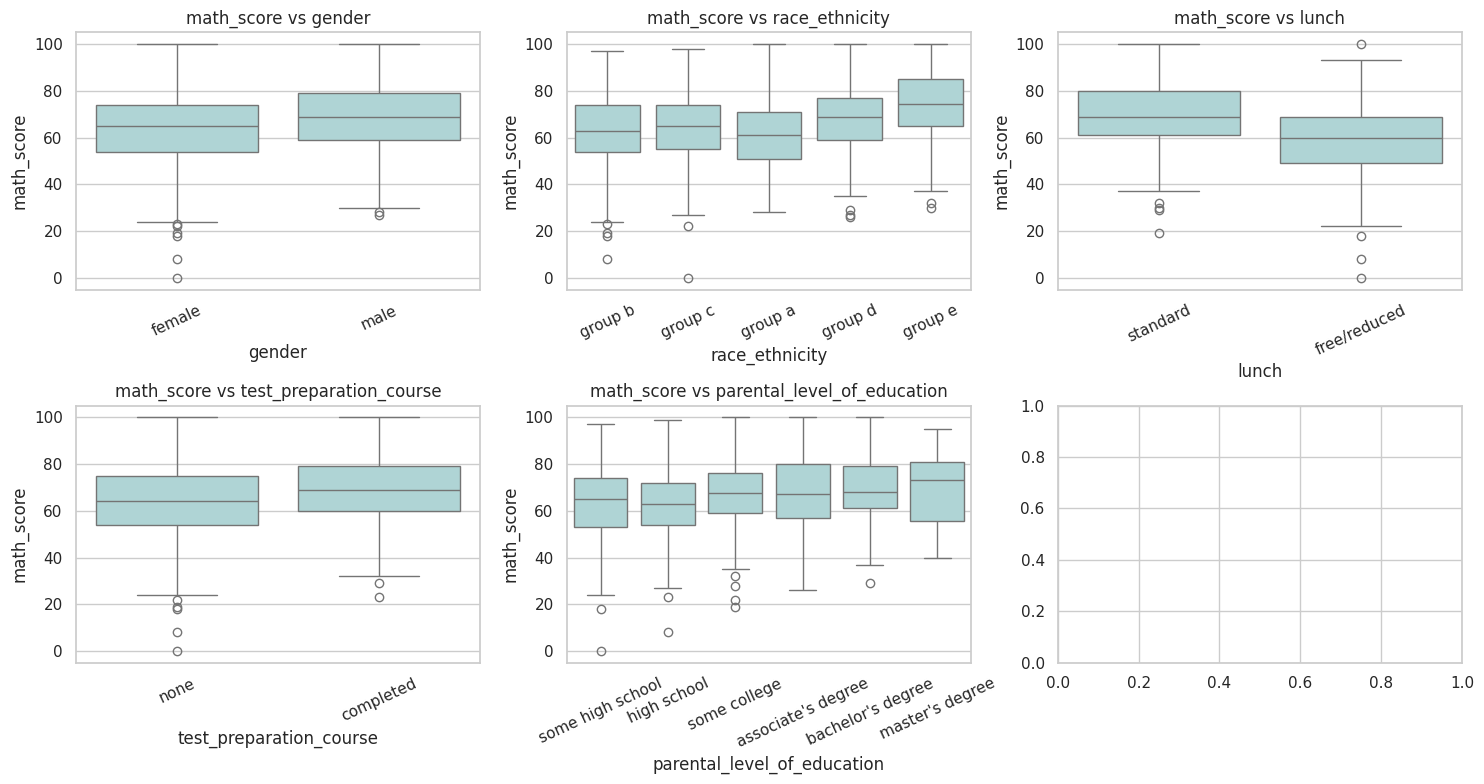


Rata-rata skor per gender:
        math_score  reading_score  writing_score
gender                                          
female        63.6           72.6           72.5
male          68.7           65.5           63.3

Rata-rata skor per race_ethnicity:
                math_score  reading_score  writing_score
race_ethnicity                                          
group a               61.6           64.7           62.7
group b               63.5           67.4           65.6
group c               64.5           69.1           67.8
group d               67.4           70.0           70.1
group e               73.8           73.0           71.4

Rata-rata skor per lunch:
              math_score  reading_score  writing_score
lunch                                                 
free/reduced        58.9           64.7           63.0
standard            70.0           71.7           70.8

Rata-rata skor per test_preparation_course:
                         math_score  reading_scor

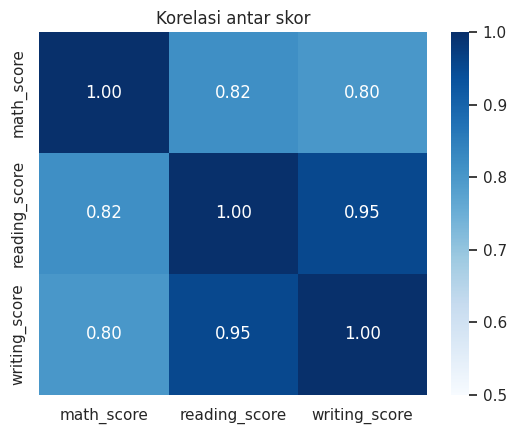

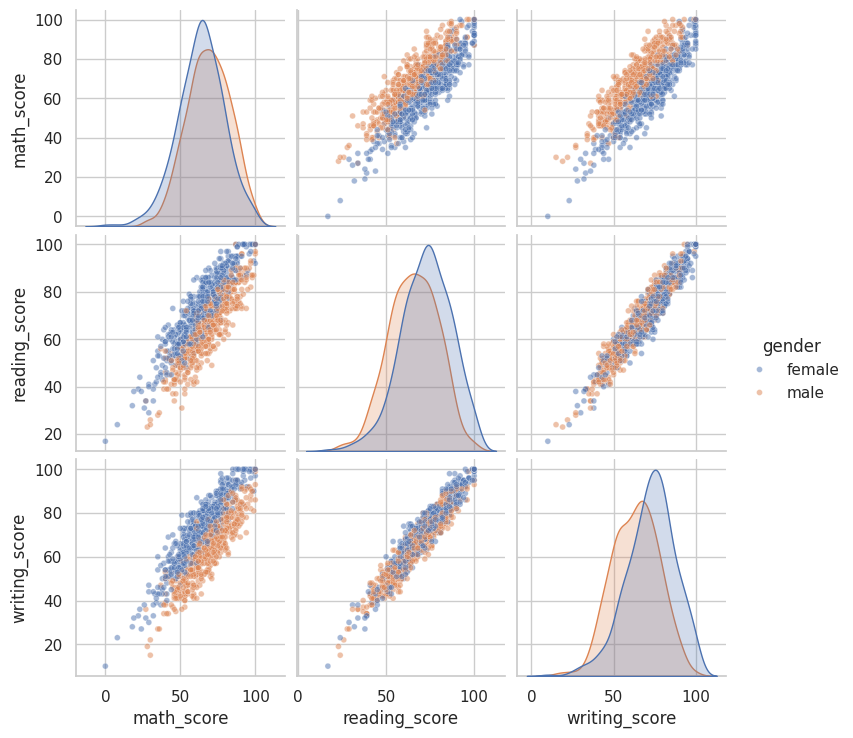

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
score_cols = ["math_score", "reading_score", "writing_score"]
ohe_cols = ["gender", "race_ethnicity", "lunch", "test_preparation_course"]
edu_order = ["some high school", "high school", "some college",
             "associate's degree", "bachelor's degree", "master's degree"]

# %%
# 1. Statistik deskriptif dan skewness
print(d[score_cols + ["average_score"]].describe().round(2))
print("\nSkewness:\n", d[score_cols].skew().round(3))

# %%
# 2. Distribusi skor (univariat)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for a, c in zip(ax, score_cols):
    sns.histplot(d[c], kde=True, ax=a, color="#219ebc")
    a.set_title(f"Distribusi {c}")
plt.tight_layout(); plt.show()

# %%
# 3. Distribusi variabel kategori
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for a, c in zip(ax.ravel(), ohe_cols):
    sns.countplot(data=d, x=c, ax=a, color="#8ecae6")
    a.set_title(c)
    a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

# %%
# 4. Math score berdasarkan tiap kategori (bivariat)
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, c in zip(ax.ravel(), ohe_cols + ["parental_level_of_education"]):
    order = edu_order if c == "parental_level_of_education" else None
    sns.boxplot(data=d, x=c, y="math_score", order=order, ax=a, color="#a8dadc")
    a.set_title(f"math_score vs {c}")
    a.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

# %%
# 5. Rata-rata skor per kategori
for c in ohe_cols + ["parental_level_of_education"]:
    print(f"\nRata-rata skor per {c}:")
    print(d.groupby(c)[score_cols].mean().round(1))

# %%
# 6. Korelasi antar skor
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(d[score_cols].corr(), annot=True, cmap="Blues", vmin=0.5, vmax=1, fmt=".2f")
plt.title("Korelasi antar skor")
plt.tight_layout(); plt.show()

# %%
# 7. Pairplot hubungan antar skor, diwarnai berdasarkan gender
sns.pairplot(d, vars=score_cols, hue="gender", plot_kws=dict(alpha=.5, s=18))
plt.show()

EDA UJI STATISTIK

Membandingkan rata-rata math_score antar kelompok, lalu menguji dengan Welch t-test (2 kelompok) atau ANOVA (lebih dari 2 kelompok).

In [ ]:

import numpy as np
import pandas as pd
from scipy import stats


# 1. Uji perbedaan rata-rata math_score
rows = []

# Variabel dengan 2 kelompok -> Welch t-test (tidak mengasumsikan varians sama)
for c in ["gender", "lunch", "test_preparation_course"]:
    g = [x.math_score.values for _, x in d.groupby(c)]
    t, p = stats.ttest_ind(*g, equal_var=False)
    pooled = np.sqrt((g[0].var(ddof=1) + g[1].var(ddof=1)) / 2)
    cohen_d = (g[0].mean() - g[1].mean()) / pooled
    rows.append([c, "Welch t-test", round(t, 3), p, round(cohen_d, 3)])

# Variabel dengan >2 kelompok -> ANOVA satu arah
for c in ["race_ethnicity", "parental_level_of_education"]:
    g = [x.math_score.values for _, x in d.groupby(c)]
    f, p = stats.f_oneway(*g)
    ssb = sum(len(x) * (x.mean() - d.math_score.mean())**2 for x in g)
    sst = ((d.math_score - d.math_score.mean())**2).sum()
    rows.append([c, "ANOVA", round(f, 3), p, round(ssb / sst, 3)])

tests = pd.DataFrame(rows, columns=["variabel", "uji", "statistik", "p_value", "effect_size (d / eta²)"])
tests["signifikan (α=0.05)"] = tests.p_value < 0.05
print(tests.to_string(index=False))

# %%
# 2. Uji normalitas math_score
print("Shapiro-Wilk math_score:", stats.shapiro(d.math_score))

# %%
# 3. Uji independensi: apakah lunch berhubungan dengan pendidikan orang tua?
ct = pd.crosstab(d.lunch, d.parental_level_of_education)
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"Chi-square lunch x pendidikan orang tua: chi2={chi2:.2f}, p={p:.4f}")

                   variabel          uji  statistik      p_value  effect_size (d / eta²)  signifikan (α=0.05)
                     gender Welch t-test     -5.398 8.420838e-08                  -0.341                 True
                      lunch Welch t-test    -11.484 5.539585e-28                  -0.770                 True
    test_preparation_course Welch t-test      5.787 1.042562e-08                   0.379                 True
             race_ethnicity        ANOVA     14.594 1.373219e-11                   0.055                 True
parental_level_of_education        ANOVA      6.522 5.592272e-06                   0.032                 True
Shapiro-Wilk math_score: ShapiroResult(statistic=np.float64(0.9931513872437832), pvalue=np.float64(0.00014545719606603633))
Chi-square lunch x pendidikan orang tua: chi2=1.11, p=0.9531


DATA SPLITTING

Membagi data menjadi dua bagian terpisah.

Train (80%, 800 siswa): dipakai model untuk belajar.
Test (20%, 200 siswa): disimpan dan hanya dipakai di akhir untuk menguji.

In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split, KFold

RS = 42  # random_state agar hasil bisa direproduksi

ord_cols = ["parental_level_of_education"]
ohe_cols = ["gender", "race_ethnicity", "lunch", "test_preparation_course"]


# 1. Tentukan target dan dua set fitur
y = d["math_score"]

# Skenario A: hanya latar belakang siswa (tanpa reading & writing)
X_A = d[ord_cols + ohe_cols]

# Skenario B: latar belakang + reading & writing score
X_B = d[ord_cols + ohe_cols + ["reading_score", "writing_score"]]

print("X_A:", X_A.shape, "| X_B:", X_B.shape, "| y:", y.shape)


# 2. Split 80% train, 20% test
# Stratifikasi pada kuartil target agar sebaran math_score di train dan test mirip
strata = pd.qcut(y, 5, duplicates="drop", labels=False)

idx_tr, idx_te = train_test_split(
    d.index, test_size=0.2, random_state=RS, stratify=strata
)

print("Train:", len(idx_tr), "| Test:", len(idx_te))
print("Rata-rata math train / test:", y[idx_tr].mean().round(2), "/", y[idx_te].mean().round(2))


# 3. Siapkan K-Fold cross-validation (5 lipatan) untuk dipakai di tahap modelling
kf = KFold(n_splits=5, shuffle=True, random_state=RS)

# Contoh: lihat ukuran tiap lipatan pada data train
for i, (a, b) in enumerate(kf.split(idx_tr), 1):
    print(f"Fold {i}: latih={len(a)}, validasi={len(b)}")

X_A: (1000, 5) | X_B: (1000, 7) | y: (1000,)
Train: 800 | Test: 200
Rata-rata math train / test: 66.28 / 65.34
Fold 1: latih=640, validasi=160
Fold 2: latih=640, validasi=160
Fold 3: latih=640, validasi=160
Fold 4: latih=640, validasi=160
Fold 5: latih=640, validasi=160


MODELING

Melatih algoritma agar menemukan pola antara fitur dan target.

In [ ]:
import pandas as pd
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# 0. Definisi variabel penunjang yang belum dibuat sebelumnya
RANDOM_STATE = RS  # Menggunakan nilai RS = 42 dari sel sebelumnya

# Memisahkan X_train dan y_train berdasarkan skenario B (menggunakan reading & writing score)
X_train = X_B.loc[idx_tr]
y_train = y.loc[idx_tr]

# Membuat preprocessor untuk data kategorikal dan numerik
categorical_features = ["parental_level_of_education", "gender", "race_ethnicity", "lunch", "test_preparation_course"]
numeric_features = ["reading_score", "writing_score"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), categorical_features)
    ]
)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

# 1. Bandingkan model dengan 5-fold cross-validation (hanya data train)
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, mdl in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", mdl)])
    r2 = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2")
    rmse = -cross_val_score(pipe, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")
    cv_rows.append([name, r2.mean(), r2.std(), rmse.mean()])

cv_df = (pd.DataFrame(cv_rows, columns=["model", "cv_r2_mean", "cv_r2_std", "cv_rmse_mean"])
         .sort_values("cv_r2_mean", ascending=False))
print("Hasil Cross-Validation (data train):")
print(cv_df.round(4).to_string(index=False))

# 2. Hyperparameter tuning (Ridge dan Gradient Boosting)
grids = {
    "Ridge": (Ridge(), {"model__alpha": [0.01, 0.1, 1, 10, 100]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE),
                          {"model__n_estimators": [100, 200],
                           "model__learning_rate": [0.03, 0.1],
                           "model__max_depth": [2, 3]}),
}
tuned = {}
for name, (mdl, grid) in grids.items():
    pipe = Pipeline([("prep", preprocessor), ("model", mdl)])
    gs = GridSearchCV(pipe, grid, cv=kf, scoring="r2", n_jobs=-1).fit(X_train, y_train)
    tuned[f"{name} (tuned)"] = gs.best_estimator_
    print(f"\n{name}: best params = {gs.best_params_} | CV R2 = {gs.best_score_:.4f}")

# 3. Latih semua model final pada data train
final_models = {n: Pipeline([("prep", preprocessor), ("model", m)]).fit(X_train, y_train)
                for n, m in models.items()}
final_models.update(tuned)
print("\nSemua model selesai dilatih:", list(final_models.keys()))

Hasil Cross-Validation (data train):
            model  cv_r2_mean  cv_r2_std  cv_rmse_mean
            Ridge      0.8659     0.0134        5.4452
Linear Regression      0.8659     0.0132        5.4467
Gradient Boosting      0.8488     0.0192        5.7738
    Random Forest      0.8232     0.0085        6.2629

Ridge: best params = {'model__alpha': 1} | CV R2 = 0.8659

Gradient Boosting: best params = {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200} | CV R2 = 0.8548

Semua model selesai dilatih: ['Linear Regression', 'Ridge', 'Random Forest', 'Gradient Boosting', 'Ridge (tuned)', 'Gradient Boosting (tuned)']


EVALUASI

Mengukur seberapa bagus model pada data test yang belum pernah dilihat.

Metrik yang dipakai:

MAE (4,33): rata-rata prediksi meleset sekitar 4 poin.
RMSE (5,30): seperti MAE tetapi lebih menghukum kesalahan besar.
R² (0,89): model menjelaskan sekitar 89% variasi nilai matematika.

Evaluasi pada data test:
                    model    MAE   RMSE     R2
        Linear Regression 4.2998 5.2747 0.8906
                    Ridge 4.3029 5.2825 0.8902
            Ridge (tuned) 4.3029 5.2825 0.8902
Gradient Boosting (tuned) 4.6786 5.6277 0.8754
        Gradient Boosting 4.7523 5.7546 0.8697
            Random Forest 4.9548 6.0343 0.8568

Model terbaik: Linear Regression


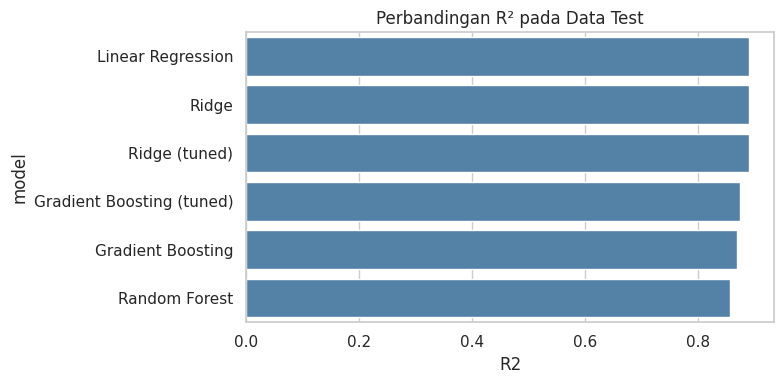

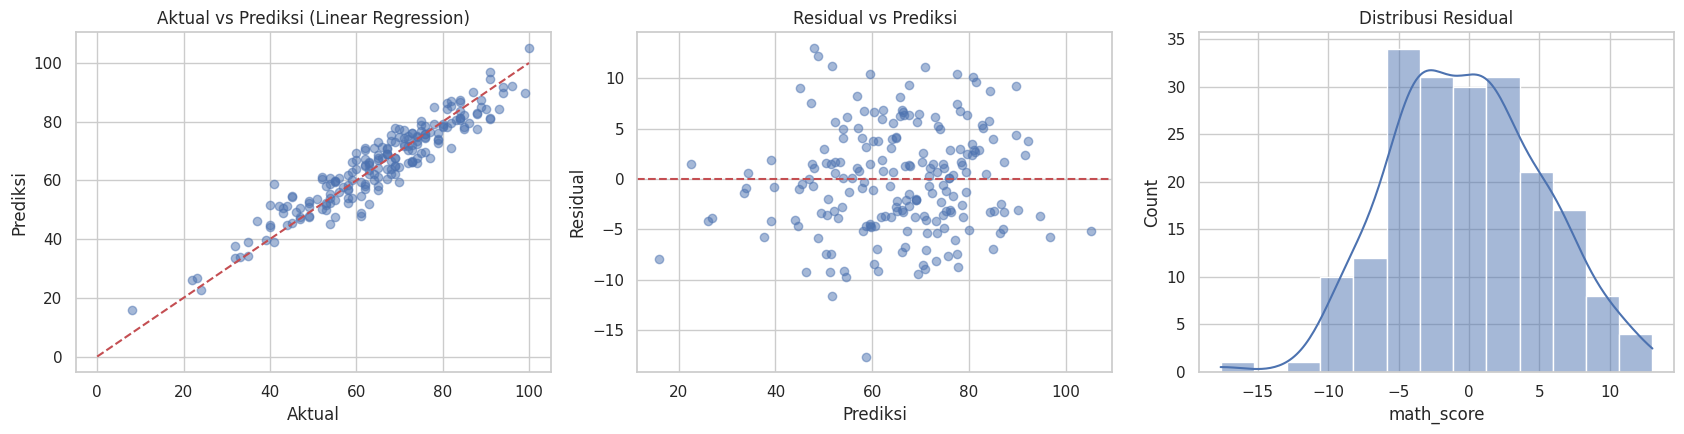

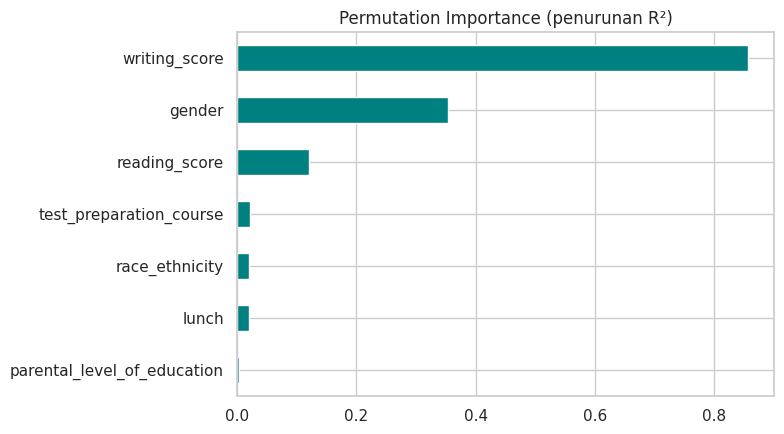

Permutation importance:
writing_score                  0.8572
gender                         0.3540
reading_score                  0.1204
test_preparation_course        0.0212
race_ethnicity                 0.0197
lunch                          0.0190
parental_level_of_education    0.0037
dtype: float64


,aktual,prediksi,selisih
674,69,67.7,1.3
61,39,39.8,-0.8
496,54,45.0,9.0
346,62,65.2,-3.2
290,76,74.5,1.5
842,23,26.9,-3.9
283,70,64.4,5.6
715,76,74.9,1.1
295,67,64.0,3.0
144,88,82.6,5.4


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

# 0. Definisikan X_test dan y_test yang sebelumnya belum dibuat
X_test = X_B.loc[idx_te]
y_test = y.loc[idx_te]

# 1. Hitung metrik semua model pada data test
rows, preds = [], {}
for name, mdl in final_models.items():
    p = mdl.predict(X_test)
    preds[name] = p
    rows.append([name, mean_absolute_error(y_test, p),
                 np.sqrt(mean_squared_error(y_test, p)), r2_score(y_test, p)])

eval_df = (pd.DataFrame(rows, columns=["model", "MAE", "RMSE", "R2"])
           .sort_values("R2", ascending=False).reset_index(drop=True))
print("Evaluasi pada data test:")
print(eval_df.round(4).to_string(index=False))

best_name = eval_df.loc[0, "model"]
best_model, best_pred = final_models[best_name], preds[best_name]
print(f"\nModel terbaik: {best_name}")

# 2. Perbandingan R² antar model
plt.figure(figsize=(8, 4))
sns.barplot(data=eval_df, y="model", x="R2", color="steelblue")
plt.title("Perbandingan R² pada Data Test")
plt.tight_layout(); plt.show()

# 3. Aktual vs prediksi, residual, distribusi residual
resid = y_test - best_pred
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(y_test, best_pred, alpha=.5)
axes[0].plot([0, 100], [0, 100], "r--")
axes[0].set(xlabel="Aktual", ylabel="Prediksi", title=f"Aktual vs Prediksi ({best_name})")
axes[1].scatter(best_pred, resid, alpha=.5)
axes[1].axhline(0, color="r", ls="--")
axes[1].set(xlabel="Prediksi", ylabel="Residual", title="Residual vs Prediksi")
sns.histplot(resid, kde=True, ax=axes[2])
axes[2].set_title("Distribusi Residual")
plt.tight_layout(); plt.show()

# 4. Feature importance (permutation importance)
perm = permutation_importance(best_model, X_test, y_test, n_repeats=20,
                              random_state=RANDOM_STATE, scoring="r2")
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
plt.figure(figsize=(8, 4.5))
imp.plot.barh(color="teal")
plt.title("Permutation Importance (penurunan R²)")
plt.tight_layout(); plt.show()
print("Permutation importance:")
print(imp.sort_values(ascending=False).round(4))

# 5. Contoh 10 prediksi
contoh = X_test.copy()
contoh["aktual"] = y_test
contoh["prediksi"] = best_pred.round(1)
contoh["selisih"] = (contoh["aktual"] - contoh["prediksi"]).round(1)
contoh[["aktual", "prediksi", "selisih"]].head(10)

SIMPAN MODEL MENGGUNAKAN JOBLIB

Joblib mengubah model yang hanya ada di memori menjadi file yang bisa dipakai ulang. Karena kita menyimpan seluruh Pipeline, bukan hanya model regresinya, proses prediksi di kemudian hari menjadi sederhana dan konsisten dengan proses pelatihan.

In [ ]:
import joblib
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score

# 1. Simpan model terbaik (sudah mencakup preprocessing, karena berbentuk Pipeline)
joblib.dump(best_model, "model_math_score.joblib")
print(f"Model '{best_name}' tersimpan sebagai model_math_score.joblib")

# 2. Muat kembali model dari file
model_loaded = joblib.load("model_math_score.joblib")

# 3. Cek bahwa hasil prediksi model yang dimuat sama dengan model asli
pred_loaded = model_loaded.predict(X_test)
print("Prediksi identik:", np.allclose(pred_loaded, best_pred))
print(f"R2 model yang dimuat: {r2_score(y_test, pred_loaded):.4f}")

# 4. Contoh prediksi untuk siswa baru
siswa_baru = pd.DataFrame([{
    "gender": "female",
    "race_ethnicity": "group C",
    "parental_level_of_education": "bachelor's degree",
    "lunch": "standard",
    "test_preparation_course": "completed",
    "reading_score": 80,
    "writing_score": 78,
}])

# Standardisasi kategori menjadi huruf kecil agar sesuai dengan data training
cat_cols_to_lower = ["gender", "race_ethnicity", "parental_level_of_education", "lunch", "test_preparation_course"]
for col in cat_cols_to_lower:
    siswa_baru[col] = siswa_baru[col].str.strip().str.lower()

siswa_baru["reading_writing_avg"] = siswa_baru[["reading_score", "writing_score"]].mean(axis=1)

prediksi = model_loaded.predict(siswa_baru)
print(f"\nPrediksi math_score untuk siswa baru: {prediksi[0]:.1f}")

Model 'Linear Regression' tersimpan sebagai model_math_score.joblib
Prediksi identik: True
R2 model yang dimuat: 0.8906

Prediksi math_score untuk siswa baru: 67.0
